In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset
from sklearn.datasets import fetch_openml

# Data preprocessing
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine Learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

# Model saving
import pickle

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load Titanic dataset
titanic = fetch_openml(
    name="titanic",
    version=1,
    as_frame=True
)

# Convert into DataFrame
df = titanic.frame

# Display first 5 rows
df.head()

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


In [3]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (1309, 14)

Column Names:
['pclass', 'survived', 'name', 'sex', 'age', 'sibsp', 'parch', 'ticket', 'fare', 'cabin', 'embarked', 'boat', 'body', 'home.dest']


In [4]:
# Check dataset information
print("Dataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Statistical summary
print("\nStatistical Summary:")
df.describe()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   pclass     1309 non-null   int64   
 1   survived   1309 non-null   category
 2   name       1309 non-null   object  
 3   sex        1309 non-null   category
 4   age        1046 non-null   float64 
 5   sibsp      1309 non-null   int64   
 6   parch      1309 non-null   int64   
 7   ticket     1309 non-null   object  
 8   fare       1308 non-null   float64 
 9   cabin      295 non-null    object  
 10  embarked   1307 non-null   category
 11  boat       486 non-null    object  
 12  body       121 non-null    float64 
 13  home.dest  745 non-null    object  
dtypes: category(3), float64(3), int64(3), object(5)
memory usage: 116.8+ KB

Missing Values:
pclass          0
survived        0
name            0
sex             0
age           263
sibsp           0
parch         

,pclass,age,sibsp,parch,fare,body
count,1309.000000,1046.000000,1309.000000,1309.000000,1308.000000,121.000000
mean,2.294882,29.881135,0.498854,0.385027,33.295479,160.809917
std,0.837836,14.413500,1.041658,0.865560,51.758668,97.696922
min,1.000000,0.166700,0.000000,0.000000,0.000000,1.000000
25%,2.000000,21.000000,0.000000,0.000000,7.895800,72.000000
50%,3.000000,28.000000,0.000000,0.000000,14.454200,155.000000
75%,3.000000,39.000000,1.000000,0.000000,31.275000,256.000000
max,3.000000,80.000000,8.000000,9.000000,512.329200,328.000000


In [5]:
# Separate target variable
X = df.drop(
    columns=[
        'survived',
        'name',
        'ticket',
        'cabin',
        'boat',
        'body',
        'home.dest'
    ]
)

# Target variable
y = df['survived'].astype(int)

# Display shapes
print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

# Display selected features
print("\nSelected Features:")
print(X.columns.tolist())

# Check target distribution
print("\nSurvival Distribution:")
print(y.value_counts())

Feature Shape: (1309, 7)
Target Shape: (1309,)

Selected Features:
['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']

Survival Distribution:
survived
0    809
1    500
Name: count, dtype: int64


In [6]:
# Identify numerical columns
numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Identify categorical columns
categorical_features = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

# Display results
print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nTotal Numerical Features:", len(numerical_features))
print("Total Categorical Features:", len(categorical_features))

Numerical Features:
['pclass', 'age', 'sibsp', 'parch', 'fare']

Categorical Features:
['sex', 'embarked']

Total Numerical Features: 5
Total Categorical Features: 2


In [7]:
# Numerical preprocessing pipeline
numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing pipeline
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both pipelines
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [8]:
# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

# Check class distribution
print("\nTraining Class Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Class Distribution:")
print(y_test.value_counts(normalize=True))

Training Features Shape: (1047, 7)
Testing Features Shape: (262, 7)

Training Target Shape: (1047,)
Testing Target Shape: (262,)

Training Class Distribution:
survived
0    0.617956
1    0.382044
Name: proportion, dtype: float64

Testing Class Distribution:
survived
0    0.618321
1    0.381679
Name: proportion, dtype: float64


In [9]:
# Define four baseline machine learning models

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        random_state=42
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        random_state=42
    )
}

# Create preprocessing + model pipelines
baseline_pipelines = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    baseline_pipelines[name] = pipeline

print("Four baseline models created successfully!")

for name in baseline_pipelines:
    print(name)

Four baseline models created successfully!
Logistic Regression
Decision Tree
Random Forest
Gradient Boosting


In [10]:
# Train all baseline models

for name, pipeline in baseline_pipelines.items():

    pipeline.fit(X_train, y_train)

    print(f"{name} trained successfully!")

print("\nAll four baseline models trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
Gradient Boosting trained successfully!

All four baseline models trained successfully!


In [11]:
# Evaluate baseline models

baseline_results = []

for name, pipeline in baseline_pipelines.items():

    # Predictions
    y_pred = pipeline.predict(X_test)

    # Prediction probabilities
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Calculate metrics
    baseline_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

# Create comparison table
baseline_comparison = pd.DataFrame(baseline_results)

# Display results
print("BASELINE MODEL COMPARISON")
display(baseline_comparison.round(4))

BASELINE MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8092,0.7717,0.71,0.7396,0.8670
1,Decision Tree,0.8015,0.7353,0.75,0.7426,0.7981
2,Random Forest,0.8015,0.7400,0.74,0.7400,0.8621
3,Gradient Boosting,0.8092,0.7841,0.69,0.7340,0.8834


In [12]:
# Configure Stratified K-Fold Cross-Validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Stratified K-Fold configured successfully!")
print("Number of folds:", cv.n_splits)
print("Shuffling:", cv.shuffle)
print("Random State:", cv.random_state)

Stratified K-Fold configured successfully!
Number of folds: 5
Shuffling: True
Random State: 42


In [13]:
# Define hyperparameter grids for all four models

param_grids = {

    'Logistic Regression': {
        'classifier__C': [0.1, 1, 10],
        'classifier__solver': ['lbfgs']
    },

    'Decision Tree': {
        'classifier__max_depth': [3, 5, 10, None],
        'classifier__min_samples_split': [2, 5],
        'classifier__min_samples_leaf': [1, 2]
    },

    'Random Forest': {
        'classifier__n_estimators': [100, 200],
        'classifier__max_depth': [5, 10, None],
        'classifier__min_samples_split': [2, 5],
        'classifier__min_samples_leaf': [1, 2]
    },

    'Gradient Boosting': {
        'classifier__n_estimators': [100, 200],
        'classifier__learning_rate': [0.05, 0.1],
        'classifier__max_depth': [2, 3]
    }
}

# Display hyperparameter configurations
for name, grid in param_grids.items():
    print(f"\n{name}:")
    for parameter, values in grid.items():
        print(f"{parameter}: {values}")

print("\nAll hyperparameter grids defined successfully!")


Logistic Regression:
classifier__C: [0.1, 1, 10]
classifier__solver: ['lbfgs']

Decision Tree:
classifier__max_depth: [3, 5, 10, None]
classifier__min_samples_split: [2, 5]
classifier__min_samples_leaf: [1, 2]

Random Forest:
classifier__n_estimators: [100, 200]
classifier__max_depth: [5, 10, None]
classifier__min_samples_split: [2, 5]
classifier__min_samples_leaf: [1, 2]

Gradient Boosting:
classifier__n_estimators: [100, 200]
classifier__learning_rate: [0.05, 0.1]
classifier__max_depth: [2, 3]

All hyperparameter grids defined successfully!


In [14]:
# Hyperparameter optimization using GridSearchCV

best_models = {}
tuning_results = []

for name, model in models.items():

    print(f"\nTuning {name}...")

    grid_search = GridSearchCV(
        estimator=baseline_pipelines[name],
        param_grid=param_grids[name],
        cv=cv,
        scoring='f1',
        n_jobs=-1,
        verbose=1
    )

    # Fit GridSearchCV
    grid_search.fit(X_train, y_train)

    # Store best model
    best_models[name] = grid_search.best_estimator_

    # Store tuning results
    tuning_results.append({
        'Model': name,
        'Best CV F1-Score': grid_search.best_score_,
        'Best Parameters': grid_search.best_params_
    })

    print("Best F1-Score:", round(grid_search.best_score_, 4))
    print("Best Parameters:", grid_search.best_params_)

print("\nAll four models tuned successfully!")

# Display tuning comparison
tuning_comparison = pd.DataFrame(tuning_results)
display(tuning_comparison)


Tuning Logistic Regression...
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Best F1-Score: 0.711
Best Parameters: {'classifier__C': 1, 'classifier__solver': 'lbfgs'}

Tuning Decision Tree...
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best F1-Score: 0.7359
Best Parameters: {'classifier__max_depth': 3, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}

Tuning Random Forest...
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best F1-Score: 0.7293
Best Parameters: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}

Tuning Gradient Boosting...
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best F1-Score: 0.7244
Best Parameters: {'classifier__learning_rate': 0.05, 'classifier__max_depth': 3, 'classifier__n_estimators': 100}

All four models tuned successfully!


,Model,Best CV F1-Score,Best Parameters
0,Logistic Regression,0.710979,"{'classifier__C': 1, 'classifier__solver': 'lb..."
1,Decision Tree,0.735918,"{'classifier__max_depth': 3, 'classifier__min_..."
2,Random Forest,0.729286,"{'classifier__max_depth': 10, 'classifier__min..."
3,Gradient Boosting,0.724420,"{'classifier__learning_rate': 0.05, 'classifie..."


In [15]:
# Evaluate all tuned models

tuned_results = []

for name, model in best_models.items():

    # Predictions
    y_pred = model.predict(X_test)

    # Prediction probabilities
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    tuned_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

# Create evaluation table
tuned_comparison = pd.DataFrame(tuned_results)

print("TUNED MODEL PERFORMANCE")
display(tuned_comparison.round(4))

TUNED MODEL PERFORMANCE


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8092,0.7717,0.71,0.7396,0.8670
1,Decision Tree,0.8359,0.8132,0.74,0.7749,0.8787
2,Random Forest,0.8359,0.8065,0.75,0.7772,0.8853
3,Gradient Boosting,0.8206,0.8193,0.68,0.7432,0.8885


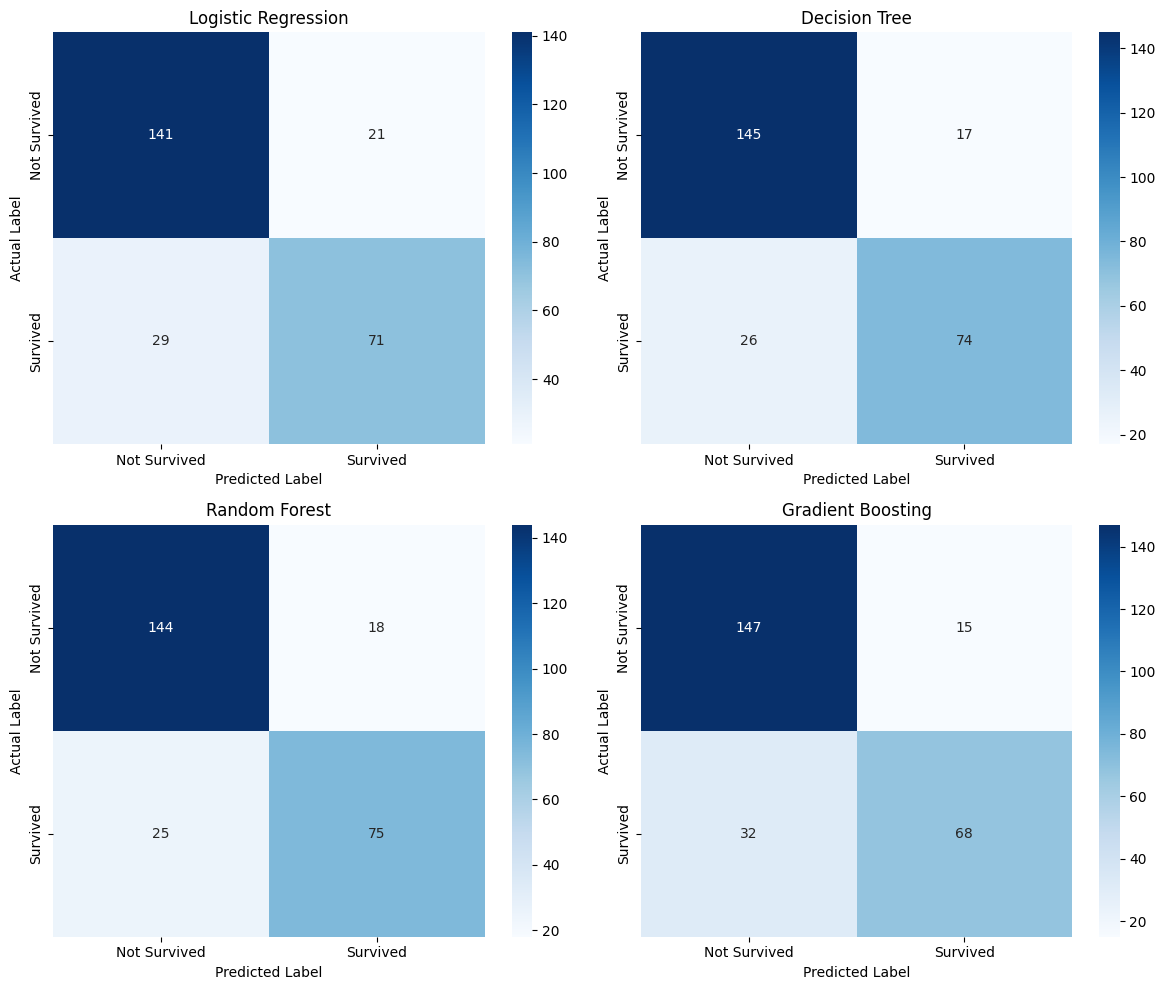

In [16]:
# Generate confusion matrices for all tuned models

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, model) in zip(axes.flatten(), best_models.items()):

    # Predictions
    y_pred = model.predict(X_test)

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    # Plot heatmap
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax,
        xticklabels=['Not Survived', 'Survived'],
        yticklabels=['Not Survived', 'Survived']
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('Actual Label')

plt.tight_layout()
plt.show()

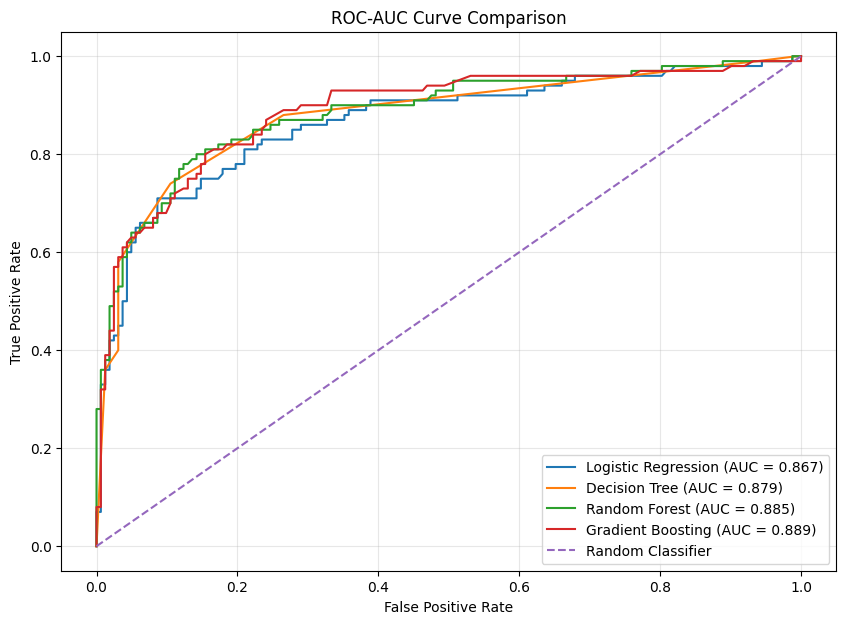

In [17]:
# Plot ROC curves for all tuned models

plt.figure(figsize=(10, 7))

for name, model in best_models.items():

    # Get prediction probabilities
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate ROC curve
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    # Calculate AUC
    auc_score = roc_auc_score(y_test, y_prob)

    # Plot ROC curve
    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {auc_score:.3f})'
    )

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Curve Comparison')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

In [18]:
# Final model comparison

final_comparison = tuned_comparison.sort_values(
    by='F1-Score',
    ascending=False
).reset_index(drop=True)

print("FINAL MODEL COMPARISON")
display(final_comparison.round(4))

# Identify champion model
champion_name = final_comparison.loc[0, 'Model']
champion_model = best_models[champion_name]

print("\nCHAMPION MODEL:", champion_name)
print("Best Test F1-Score:",
      round(final_comparison.loc[0, 'F1-Score'], 4))

print("Best Test ROC-AUC:",
      round(final_comparison.loc[0, 'ROC-AUC'], 4))

FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.8359,0.8065,0.75,0.7772,0.8853
1,Decision Tree,0.8359,0.8132,0.74,0.7749,0.8787
2,Gradient Boosting,0.8206,0.8193,0.68,0.7432,0.8885
3,Logistic Regression,0.8092,0.7717,0.71,0.7396,0.8670



CHAMPION MODEL: Random Forest
Best Test F1-Score: 0.7772
Best Test ROC-AUC: 0.8853


In [19]:
# Save the champion model

model_filename = 'champion_model.pkl'

with open(model_filename, 'wb') as file:
    pickle.dump(champion_model, file)

print("Champion model saved successfully!")
print("Model Name:", champion_name)
print("File Name:", model_filename)

Champion model saved successfully!
Model Name: Random Forest
File Name: champion_model.pkl


In [20]:
from google.colab import files

files.download('champion_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
# Load the saved champion model

with open('champion_model.pkl', 'rb') as file:
    loaded_model = pickle.load(file)

# Make predictions using loaded model
sample_predictions = loaded_model.predict(X_test.iloc[:5])

print("Model loaded successfully!")
print("\nFirst 5 Predictions:", sample_predictions)
print("Actual Values:", y_test.iloc[:5].values)

print("\nModel verification completed successfully!")

Model loaded successfully!

First 5 Predictions: [1 1 0 0 0]
Actual Values: [1 1 0 0 0]

Model verification completed successfully!


In [22]:
# Generate classification report

champion_predictions = champion_model.predict(X_test)

print("CHAMPION MODEL:", champion_name)
print("\nClassification Report:\n")

print(classification_report(
    y_test,
    champion_predictions,
    target_names=['Not Survived', 'Survived']
))

CHAMPION MODEL: Random Forest

Classification Report:

              precision    recall  f1-score   support

Not Survived       0.85      0.89      0.87       162
    Survived       0.81      0.75      0.78       100

    accuracy                           0.84       262
   macro avg       0.83      0.82      0.82       262
weighted avg       0.83      0.84      0.83       262



,Feature,Importance
6,cat__sex_male,0.220717
4,num__fare,0.207649
1,num__age,0.172015
5,cat__sex_female,0.166081
0,num__pclass,0.103115
2,num__sibsp,0.047481
3,num__parch,0.038363
7,cat__embarked_C,0.026688
9,cat__embarked_S,0.011796
8,cat__embarked_Q,0.006096


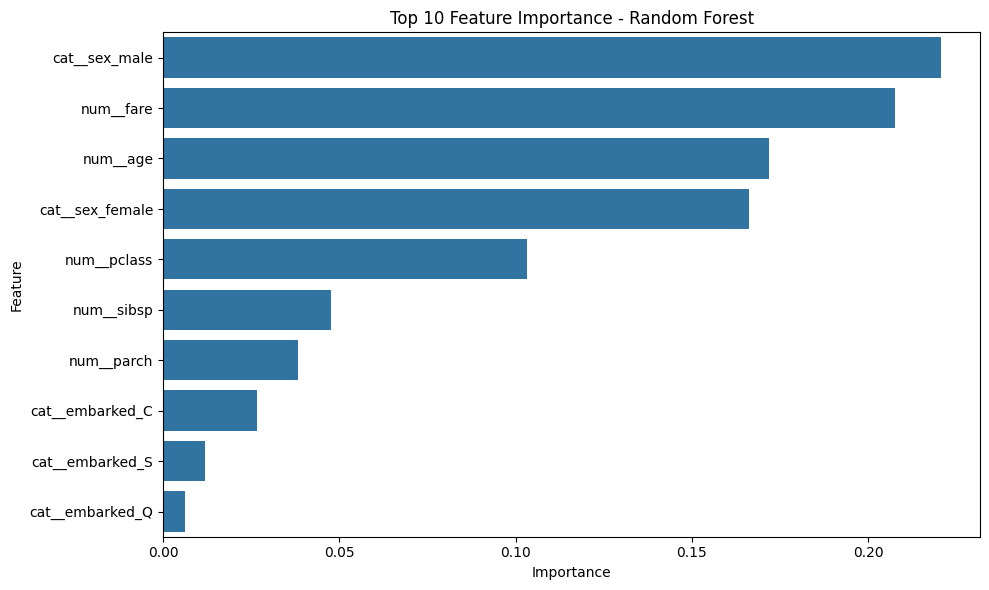

In [23]:
# Extract feature importance from champion model

classifier = champion_model.named_steps['classifier']
preprocessor_fitted = champion_model.named_steps['preprocessor']

feature_names = preprocessor_fitted.get_feature_names_out()

if hasattr(classifier, 'feature_importances_'):
    importance = classifier.feature_importances_

elif hasattr(classifier, 'coef_'):
    importance = np.abs(classifier.coef_[0])

else:
    raise ValueError("Feature importance is unavailable.")

# Create feature importance DataFrame
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
}).sort_values(
    by='Importance',
    ascending=False
)

# Display top features
display(feature_importance.head(10))

# Plot feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title(f'Top 10 Feature Importance - {champion_name}')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# Supervised Classification Modeling & Hyperparameter Tuning

## Project Overview
This project focuses on developing and comparing multiple supervised machine learning classification algorithms to predict passenger survival using the Titanic dataset.

## Dataset
- Dataset: Titanic Survival Dataset
- Total Records: 1,309
- Total Features: 14
- Target Variable: `survived`

## Data Preprocessing
- Missing value imputation
- Standard scaling for numerical features
- One-hot encoding for categorical features
- Train-test split (80:20)
- Stratified sampling

## Machine Learning Algorithms
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Gradient Boosting

## Hyperparameter Optimization
- GridSearchCV
- Stratified 5-Fold Cross-Validation
- F1-score optimization

## Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Confusion Matrix
- Classification Report

## Model Selection
The champion model was selected based on its test-set F1-score after hyperparameter tuning.

## Model Deployment Artifact
The selected model was serialized and saved as `champion_model.pkl`.

## Conclusion
This project demonstrates a complete supervised classification workflow, including preprocessing, model training, hyperparameter optimization, performance evaluation, model comparison and model serialization.

In [24]:
# Final Project Verification

print("SUPERVISED CLASSIFICATION PROJECT")
print("=" * 45)

print("1. Dataset Loaded: YES")
print("2. Preprocessing Pipeline: YES")
print("3. Train-Test Split: YES")
print("4. Four Baseline Models: YES")
print("5. GridSearchCV Optimization: YES")
print("6. Stratified 5-Fold CV: YES")
print("7. Confusion Matrices: YES")
print("8. ROC-AUC Curves: YES")
print("9. Classification Report: YES")
print("10. Feature Importance: YES")
print("11. Champion Model: ", champion_name)

print("\nModel Performance:")
display(final_comparison.round(4))

print("\nSaved Model File:")
import os
print("champion_model.pkl:",
      os.path.exists("champion_model.pkl"))

print("\nPROJECT VERIFICATION COMPLETED!")

SUPERVISED CLASSIFICATION PROJECT
1. Dataset Loaded: YES
2. Preprocessing Pipeline: YES
3. Train-Test Split: YES
4. Four Baseline Models: YES
5. GridSearchCV Optimization: YES
6. Stratified 5-Fold CV: YES
7. Confusion Matrices: YES
8. ROC-AUC Curves: YES
9. Classification Report: YES
10. Feature Importance: YES
11. Champion Model:  Random Forest

Model Performance:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.8359,0.8065,0.75,0.7772,0.8853
1,Decision Tree,0.8359,0.8132,0.74,0.7749,0.8787
2,Gradient Boosting,0.8206,0.8193,0.68,0.7432,0.8885
3,Logistic Regression,0.8092,0.7717,0.71,0.7396,0.8670



Saved Model File:
champion_model.pkl: True

PROJECT VERIFICATION COMPLETED!
